In [ ]:
!pip install shap==0.44.1 numpy==1.26.4 numba==0.59.1 pandas scikit-learn matplotlib seaborn fairlearn aif360 tensorflow


In [ ]:
import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight

from fairlearn.postprocessing import ThresholdOptimizer
from fairlearn.metrics import demographic_parity_difference, equalized_odds_difference

from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.inprocessing import AdversarialDebiasing
from aif360.metrics import ClassificationMetric


pip install 'aif360[inFairness]'


In [ ]:
def fairness_metrics(y_true, y_pred, protected):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    protected = np.array(protected)

    mask1 = protected == 1
    mask0 = protected == 0

    def safe_mean(arr):
        return np.mean(arr) if arr.size > 0 else 0

    rate1 = safe_mean(y_pred[mask1])
    rate0 = safe_mean(y_pred[mask0])

    dp = rate1 - rate0
    di = rate0 / rate1 if rate1 != 0 else 0

    tpr1 = safe_mean(y_pred[(y_true==1) & mask1])
    tpr0 = safe_mean(y_pred[(y_true==1) & mask0])
    eo = tpr1 - tpr0

    return dp, di, eo


In [ ]:
cols = ["age","workclass","fnlwgt","education","education-num",
        "marital-status","occupation","relationship","race","sex",
        "capital-gain","capital-loss","hours-per-week","native-country","income"]

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
adult = pd.read_csv(url, names=cols, na_values=" ?", skipinitialspace=True).dropna()

adult["income"] = adult["income"].apply(lambda x: 1 if ">50K" in x else 0)
protected_adult = adult["sex"].apply(lambda x: 1 if x=="Male" else 0)

le = LabelEncoder()
for col in adult.select_dtypes(include="object").columns:
    adult[col] = le.fit_transform(adult[col])


In [ ]:
X = adult.drop("income", axis=1)
y = adult["income"]

X_train, X_test, y_train, y_test, prot_train, prot_test = train_test_split(
    X, y, protected_adult, stratify=protected_adult, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
feature_names = X.columns


In [ ]:
lr = LogisticRegression(max_iter=3000)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

lr.fit(X_train, y_train)
rf.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
y_pred_rf = rf.predict(X_test)

dp_lr, di_lr, eo_lr = fairness_metrics(y_test, y_pred_lr, prot_test)
dp_rf, di_rf, eo_rf = fairness_metrics(y_test, y_pred_rf, prot_test)


In [ ]:
weights = compute_sample_weight(class_weight="balanced", y=y_train)
lr_rw = LogisticRegression(max_iter=3000)
lr_rw.fit(X_train, y_train, sample_weight=weights)

y_pred_rw = lr_rw.predict(X_test)
dp_rw, di_rw, eo_rw = fairness_metrics(y_test, y_pred_rw, prot_test)


In [ ]:
thresh = ThresholdOptimizer(
    estimator=lr,
    constraints="demographic_parity",
    predict_method="predict_proba"
)
thresh.fit(X_train, y_train, sensitive_features=prot_train)

y_pred_thresh = thresh.predict(X_test, sensitive_features=prot_test)
dp_thresh = demographic_parity_difference(y_test, y_pred_thresh, sensitive_features=prot_test)
eo_thresh = equalized_odds_difference(y_test, y_pred_thresh, sensitive_features=prot_test)


In [ ]:
tf.compat.v1.disable_eager_execution()

train_df = pd.DataFrame(X_train, columns=feature_names)
train_df["income"] = y_train.values
train_df["sex"] = prot_train.values

test_df = pd.DataFrame(X_test, columns=feature_names)
test_df["income"] = y_test.values
test_df["sex"] = prot_test.values

aif_train = BinaryLabelDataset(df=train_df, label_names=["income"], protected_attribute_names=["sex"])
aif_test = BinaryLabelDataset(df=test_df, label_names=["income"], protected_attribute_names=["sex"])

tf.compat.v1.reset_default_graph()
sess = tf.compat.v1.Session()

adv = AdversarialDebiasing(
    privileged_groups=[{"sex":1}],
    unprivileged_groups=[{"sex":0}],
    scope_name="adv_adult",
    sess=sess
)

adv.fit(aif_train)
pred_adv = adv.predict(aif_test)

metric_adv = ClassificationMetric(
    aif_test, pred_adv,
    privileged_groups=[{"sex":1}],
    unprivileged_groups=[{"sex":0}]
)

dp_adv = metric_adv.statistical_parity_difference()
eo_adv = metric_adv.equal_opportunity_difference()


Instructions for updating:
Please use `rate` instead of `keep_prob`. Rate should be set to `rate = 1 - keep_prob`.


epoch 0; iter: 0; batch classifier loss: 0.684305; batch adversarial loss: 0.771920
epoch 0; iter: 200; batch classifier loss: 0.471875; batch adversarial loss: 0.723041
epoch 1; iter: 0; batch classifier loss: 0.453679; batch adversarial loss: 0.715291
epoch 1; iter: 200; batch classifier loss: 0.349191; batch adversarial loss: 0.641678
epoch 2; iter: 0; batch classifier loss: 0.331902; batch adversarial loss: 0.666400
epoch 2; iter: 200; batch classifier loss: 0.417193; batch adversarial loss: 0.656450
epoch 3; iter: 0; batch classifier loss: 0.333971; batch adversarial loss: 0.625862
epoch 3; iter: 200; batch classifier loss: 0.341772; batch adversarial loss: 0.629034
epoch 4; iter: 0; batch classifier loss: 0.368193; batch adversarial loss: 0.625521
epoch 4; iter: 200; batch classifier loss: 0.445687; batch adversarial loss: 0.651739
epoch 5; iter: 0; batch classifier loss: 0.329812; batch adversarial loss: 0.594820
epoch 5; iter: 200; batch classifier loss: 0.308032; batch adversa

100%|===================| 13017/13026 [14:53<00:00]       

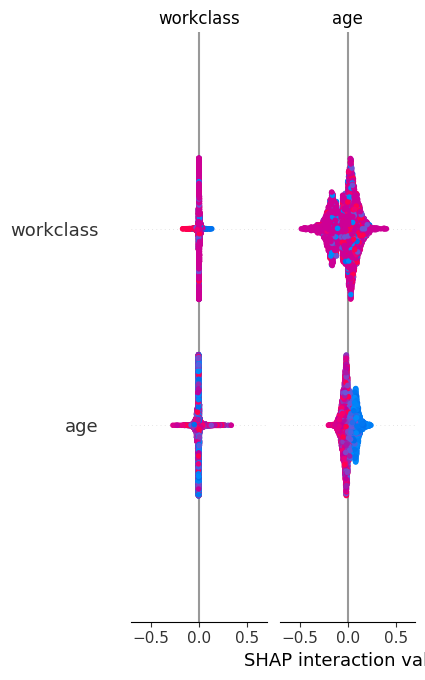

In [ ]:
import shap
explainer = shap.TreeExplainer(rf, X_train)
shap_values = explainer(X_test, check_additivity=False)
shap.summary_plot(shap_values, X_test, feature_names=feature_names)

In [ ]:
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
compas = pd.read_csv(url)

compas = compas[["age","race","sex","priors_count","two_year_recid"]].dropna()
compas["race"] = compas["race"].apply(lambda x: 1 if x=="Caucasian" else 0)
compas["sex"] = compas["sex"].apply(lambda x: 1 if x=="Male" else 0)

X = compas.drop("two_year_recid", axis=1)
y = compas["two_year_recid"]
protected = compas["race"]


In [ ]:
X_train, X_test, y_train, y_test, prot_train, prot_test = train_test_split(
    X, y, protected, stratify=protected, test_size=0.2, random_state=42
)


In [ ]:
lr_c = LogisticRegression(max_iter=3000)
rf_c = RandomForestClassifier(n_estimators=100, random_state=42)

lr_c.fit(X_train, y_train)
rf_c.fit(X_train, y_train)

y_pred_lr_c = lr_c.predict(X_test)
y_pred_rf_c = rf_c.predict(X_test)

dp_c_lr, di_c_lr, eo_c_lr = fairness_metrics(y_test, y_pred_lr_c, prot_test)
dp_c_rf, di_c_rf, eo_c_rf = fairness_metrics(y_test, y_pred_rf_c, prot_test)


In [ ]:
thresh_c = ThresholdOptimizer(
    estimator=lr_c,
    constraints="demographic_parity",
    predict_method="predict_proba"
)

thresh_c.fit(X_train, y_train, sensitive_features=prot_train)
y_pred_thresh_c = thresh_c.predict(X_test, sensitive_features=prot_test)

dp_thresh_c = demographic_parity_difference(y_test, y_pred_thresh_c, sensitive_features=prot_test)
eo_thresh_c = equalized_odds_difference(y_test, y_pred_thresh_c, sensitive_features=prot_test)


In [ ]:
tf.compat.v1.disable_eager_execution()

compas_aif = compas.copy()

aif_data = BinaryLabelDataset(
    df=compas_aif,
    label_names=["two_year_recid"],
    protected_attribute_names=["race"]
)

train_aif, test_aif = aif_data.split([0.8], shuffle=True)

tf.compat.v1.reset_default_graph()
sess = tf.compat.v1.Session()

adv_c = AdversarialDebiasing(
    privileged_groups=[{"race":1}],
    unprivileged_groups=[{"race":0}],
    scope_name="adv_compas",
    sess=sess
)

adv_c.fit(train_aif)
pred_adv_c = adv_c.predict(test_aif)

metric_adv_c = ClassificationMetric(
    test_aif, pred_adv_c,
    privileged_groups=[{"race":1}],
    unprivileged_groups=[{"race":0}]
)

dp_adv_c = metric_adv_c.statistical_parity_difference()
eo_adv_c = metric_adv_c.equal_opportunity_difference()

epoch 0; iter: 0; batch classifier loss: 1.418077; batch adversarial loss: 0.928510
epoch 1; iter: 0; batch classifier loss: 0.894158; batch adversarial loss: 0.850914
epoch 2; iter: 0; batch classifier loss: 0.694153; batch adversarial loss: 0.932222
epoch 3; iter: 0; batch classifier loss: 0.796278; batch adversarial loss: 0.813451
epoch 4; iter: 0; batch classifier loss: 0.668475; batch adversarial loss: 0.789842
epoch 5; iter: 0; batch classifier loss: 0.691617; batch adversarial loss: 0.793085
epoch 6; iter: 0; batch classifier loss: 0.591907; batch adversarial loss: 0.783565
epoch 7; iter: 0; batch classifier loss: 0.560322; batch adversarial loss: 0.753480
epoch 8; iter: 0; batch classifier loss: 0.698443; batch adversarial loss: 0.719756
epoch 9; iter: 0; batch classifier loss: 0.666901; batch adversarial loss: 0.682822
epoch 10; iter: 0; batch classifier loss: 0.639223; batch adversarial loss: 0.687961
epoch 11; iter: 0; batch classifier loss: 0.619347; batch adversarial loss:

 99%|===================| 2856/2886 [00:51<00:00]       

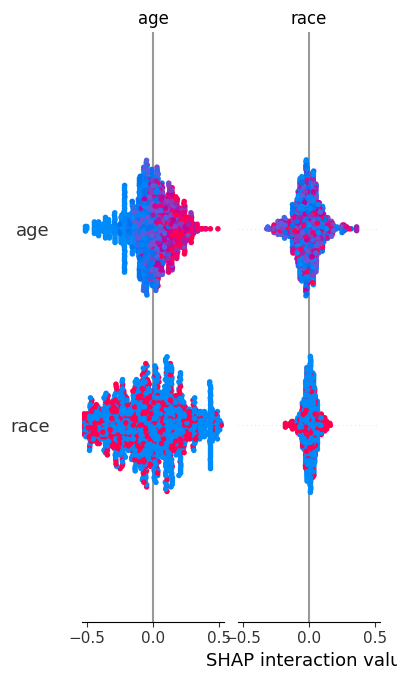

In [ ]:
explainer_c = shap.TreeExplainer(rf_c, X_train)
shap_vals_c = explainer_c(X_test, check_additivity=False)
shap.summary_plot(shap_vals_c, X_test, feature_names=X.columns)

In [ ]:
results_adult = pd.DataFrame({
    "Model":["LR","RF","Reweighting","ThresholdAdj","Adversarial"],
    "DP":[dp_lr, dp_rf, dp_rw, dp_thresh, dp_adv],
    "EO":[eo_lr, eo_rf, eo_rw, eo_thresh, eo_adv]
})

results_compas = pd.DataFrame({
    "Model":["LR","RF","ThresholdAdj","Adversarial"],
    "DP":[dp_c_lr, dp_c_rf, dp_thresh_c, dp_adv_c],
    "EO":[eo_c_lr, eo_c_rf, eo_thresh_c, eo_adv_c]
})

results_adult, results_compas


(          Model        DP        EO
 0            LR  0.175998  0.277065
 1            RF  0.185314  0.109124
 2   Reweighting  0.345397  0.380068
 3  ThresholdAdj  0.006781  0.115531
 4   Adversarial -0.046283  0.172259,
           Model        DP        EO
 0            LR -0.160141 -0.180470
 1            RF -0.076702 -0.090270
 2  ThresholdAdj  0.012823  0.069626
 3   Adversarial  0.060832  0.054709)

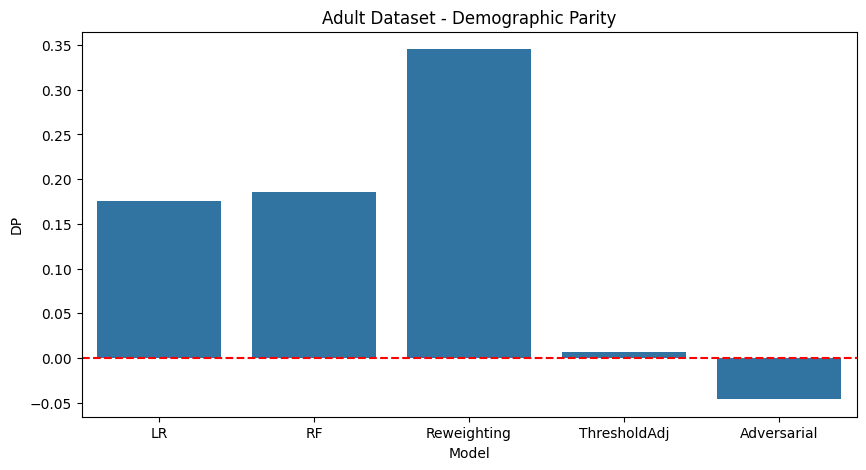

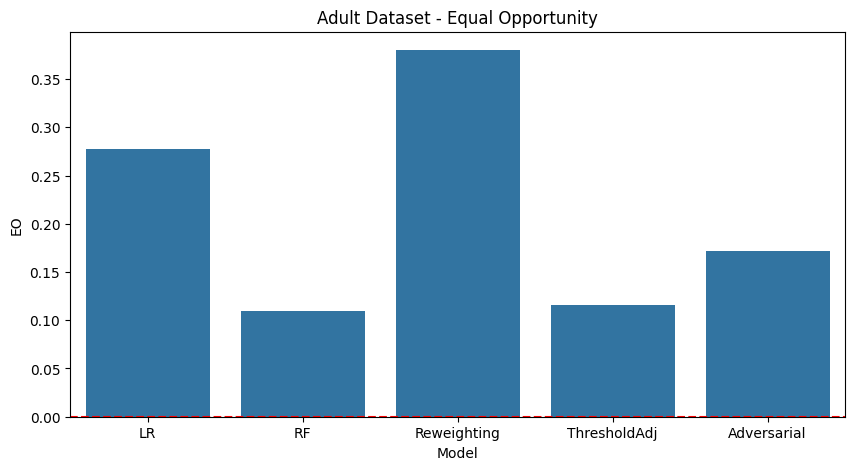

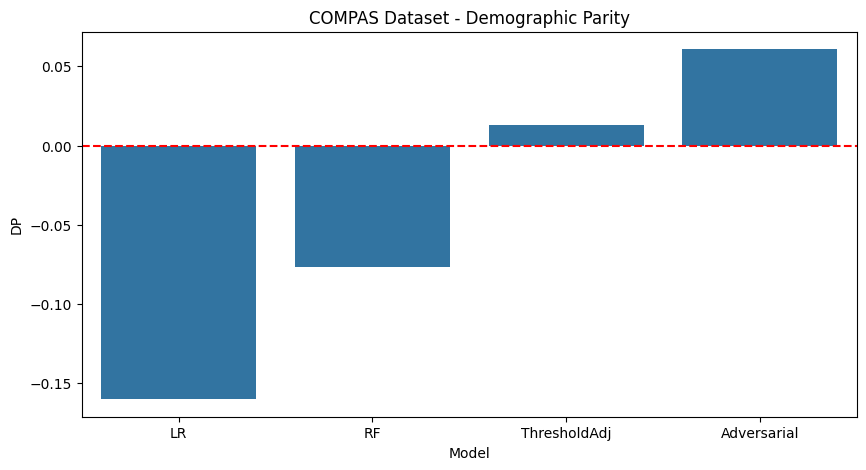

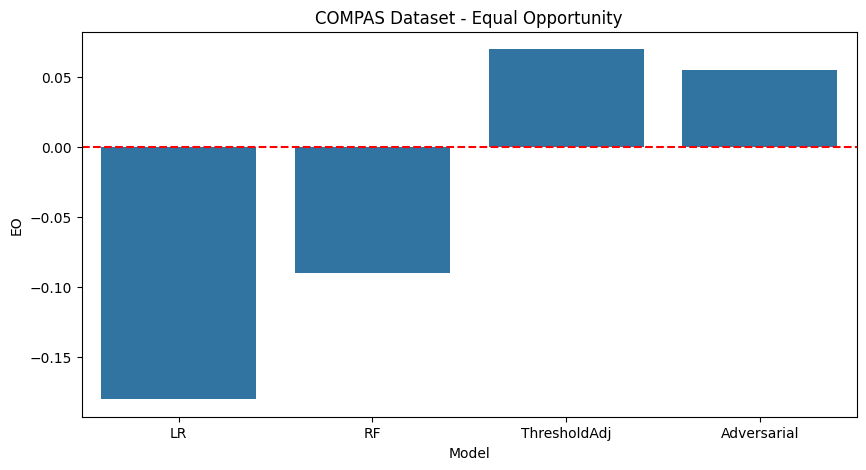

In [ ]:
plt.figure(figsize=(10,5))
sns.barplot(x="Model", y="DP", data=results_adult)
plt.axhline(0,color="red",linestyle="--")
plt.title("Adult Dataset - Demographic Parity")
plt.show()

plt.figure(figsize=(10,5))
sns.barplot(x="Model", y="EO", data=results_adult)
plt.axhline(0,color="red",linestyle="--")
plt.title("Adult Dataset - Equal Opportunity")
plt.show()

plt.figure(figsize=(10,5))
sns.barplot(x="Model", y="DP", data=results_compas)
plt.axhline(0,color="red",linestyle="--")
plt.title("COMPAS Dataset - Demographic Parity")
plt.show()

plt.figure(figsize=(10,5))
sns.barplot(x="Model", y="EO", data=results_compas)
plt.axhline(0,color="red",linestyle="--")
plt.title("COMPAS Dataset - Equal Opportunity")
plt.show()
